In [2]:
import snntorch as snn 
import torch

In [3]:
batch_size=128
data_path='/tmp/data/mnist'
num_classes = 10  # MNIST has 10 output classes

# Torch Variables
dtype = torch.float

In [4]:
from torchvision import datasets, transforms

# Define a transform
transform = transforms.Compose([
            transforms.Resize((28,28)),
            transforms.Grayscale(),
            transforms.ToTensor(),
            transforms.Normalize((0,), (1,))])

mnist_train = datasets.MNIST(data_path, train=True, download=True, transform=transform)


100%|██████████| 9.91M/9.91M [01:03<00:00, 156kB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 151kB/s]
100%|██████████| 1.65M/1.65M [00:10<00:00, 157kB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 107kB/s]


In [5]:
from snntorch import utils

subset = 10
mnist_train = utils.data_subset(mnist_train, subset)
print(f"The size of mnist_train is {len(mnist_train)}")


The size of mnist_train is 6000


In [6]:
from torch.utils.data import DataLoader

train_loader = DataLoader(mnist_train, batch_size=batch_size, shuffle=True)

In [11]:
num_steps = 100

# create vector filled with 0.5
raw_vector = torch.ones(num_steps)*0.5

# pass each sample through a Bernoulli trial
rate_coded_vector = torch.bernoulli(raw_vector)
print(rate_coded_vector)

tensor([0., 0., 0., 0., 1., 1., 0., 0., 1., 0., 0., 1., 1., 0., 1., 0., 1., 0.,
        0., 0., 0., 0., 1., 1., 0., 0., 0., 1., 0., 0., 0., 0., 1., 1., 1., 0.,
        1., 1., 0., 1., 1., 1., 1., 0., 0., 0., 1., 1., 1., 1., 1., 1., 0., 0.,
        0., 0., 1., 0., 1., 1., 1., 1., 1., 1., 1., 0., 1., 0., 0., 1., 0., 1.,
        0., 1., 1., 1., 0., 0., 0., 0., 0., 1., 1., 0., 1., 1., 0., 0., 0., 1.,
        0., 1., 0., 1., 1., 0., 0., 0., 1., 0.])


In [12]:
from snntorch import spikegen

# Iterate through minibatches
data = iter(train_loader)
data_it, targets_it = next(data)

# Spiking Data
spike_data = spikegen.rate(data_it, num_steps=num_steps)


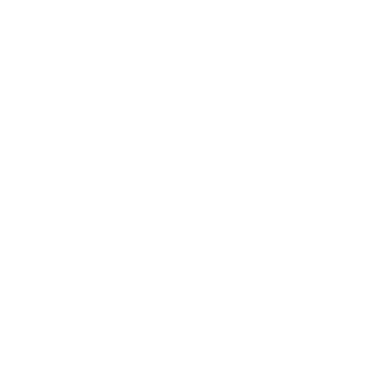

In [16]:
import matplotlib.pyplot as plt
import snntorch.spikeplot as splt
from IPython.display import HTML
spike_data_sample = spike_data[:, 0, 0]
fig, ax = plt.subplots()
anim = splt.animator(spike_data_sample, fig, ax)
